# Lab 4. Domain decomposition methods

Variant 7: task 1 — №4, task 2 — №11.

In [1]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse.linalg import splu
from scipy.linalg import solve_banded
import matplotlib.pyplot as plt

### Iteration on the interface

$$
\lambda^{k+1} = \lambda^k + \theta\, R(\lambda^k), \qquad \|\lambda^{k+1} - \lambda^k\| < \varepsilon
$$

In [2]:
def iterate(step, lam, theta, eps=1e-8, kmax=5000, keep=50):
    lam = np.array(lam, dtype=float)
    Us, errs = [], []
    for k in range(kmax):
        U, R = step(lam)
        lam += theta * R
        errs.append(np.abs(theta * R).max())
        if k < keep:
            Us.append(U)
        if errs[-1] < eps or not np.isfinite(errs[-1]):
            break
    Us.append(U)
    return Us, errs

## 1. 1D problem

$$
(2 + \cos e^{-x})\,y'' + x\,y' - 3y = \sin\!\left(e^{-x^2} + 2\right), \quad x \in [-1, 2],
\qquad y'(-1) = 0, \quad y(2) = 2
$$

$$
a_i y_{i-1} + b_i y_i + c_i y_{i+1} = f_i, \qquad
a_i = \frac{p_i}{h^2} - \frac{q_i}{2h},\quad b_i = -\frac{2p_i}{h^2} + r_i,\quad c_i = \frac{p_i}{h^2} + \frac{q_i}{2h}
$$

Neumann $y' = g$: ghost node $y_{-1} = y_1 - 2hg$.

In [3]:
p = lambda x: 2 + np.cos(np.exp(-x))
q = lambda x: x
r = lambda x: -3 + 0 * x
f = lambda x: np.sin(np.exp(-x**2) + 2)


def coefs(x):
    h = x[1] - x[0]
    return p(x) / h**2 - q(x) / (2 * h), -2 * p(x) / h**2 + r(x), p(x) / h**2 + q(x) / (2 * h)


def solve1d(xa, xb, n, left, right):
    # left, right: ("D", y) or ("N", y')
    x = np.linspace(xa, xb, n + 1)
    h = x[1] - x[0]
    a, b, c = coefs(x)
    d = f(x)
    if left[0] == "D":
        b[0], c[0], d[0] = 1, 0, left[1]
    else:
        c[0], d[0] = c[0] + a[0], d[0] + 2 * h * left[1] * a[0]
    if right[0] == "D":
        a[-1], b[-1], d[-1] = 0, 1, right[1]
    else:
        a[-1], d[-1] = a[-1] + c[-1], d[-1] - 2 * h * right[1] * c[-1]
    ab = np.array([np.r_[0, c[:-1]], b, np.r_[a[1:], 0]])
    return x, solve_banded((1, 1), ab, d)


def flux1d(x, y, side):
    # y' at the end node, ghost node taken from the equation
    h = x[1] - x[0]
    a, b, c = coefs(x)
    if side == "R":
        ghost = (f(x[-1]) - a[-1] * y[-2] - b[-1] * y[-1]) / c[-1]
        return (ghost - y[-2]) / (2 * h)
    ghost = (f(x[0]) - b[0] * y[0] - c[0] * y[1]) / a[0]
    return (y[1] - ghost) / (2 * h)

In [4]:
N1, nc = 300, 150                          # Γ: x = 0.5
xg, yg = solve1d(-1, 2, N1, ("N", 0), ("D", 2))


def show1d(Us, errs, title):
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
    fig.suptitle(f"{title}: {len(errs)} iterations")
    for x1, u1, x2, u2 in Us[:-1]:
        ax[0].plot(x1, u1, "b", lw=0.8)
        ax[0].plot(x2, u2, "g", lw=0.8)
    ax[0].set_title("Iterations")
    x1, u1, x2, u2 = Us[-1]
    ax[1].plot(x1, u1, "b", lw=2, label="Subdomain 1")
    ax[1].plot(x2, u2, "g", lw=2, label="Subdomain 2")
    ax[1].plot(xg[::10], yg[::10], "r.", label="Whole domain")
    ax[1].set_title("Result")
    ax[1].legend()
    ax[2].semilogy(errs, "o-", ms=3)
    ax[2].set_title(r"$|\lambda^{k+1} - \lambda^k|$")
    for a in ax:
        a.grid()
    plt.show()
    print(f"max|u - y_whole| = {max(abs(u1 - yg[:nc + 1]).max(), abs(u2 - yg[nc:]).max()):.2e}")

### 1.1. Neumann–Dirichlet

$$
u_1\big|_\Gamma = \lambda^k, \qquad u_2'\big|_\Gamma = u_1'\big|_\Gamma, \qquad R = u_2\big|_\Gamma - \lambda^k
$$

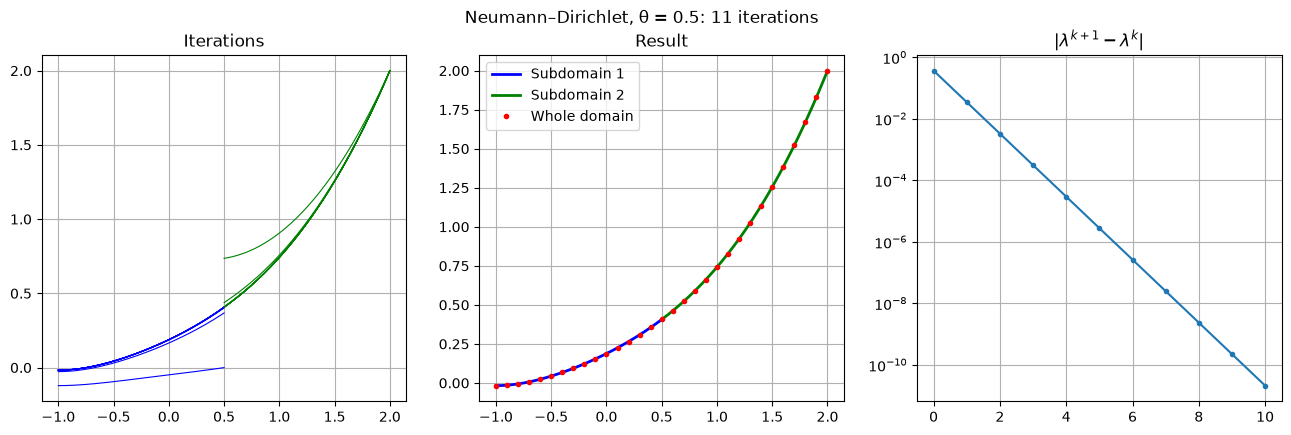

max|u - y_whole| = 2.33e-11


In [5]:
def nd1d(lam):
    x1, u1 = solve1d(-1, 0.5, nc, ("N", 0), ("D", lam))
    x2, u2 = solve1d(0.5, 2, N1 - nc, ("N", flux1d(x1, u1, "R")), ("D", 2))
    return (x1, u1, x2, u2), u2[0] - lam


show1d(*iterate(nd1d, 0, theta=0.5, eps=1e-10), "Neumann–Dirichlet, θ = 0.5")

### 1.2. Dirichlet–Dirichlet

$$
u_1\big|_\Gamma = u_2\big|_\Gamma = \lambda^k, \qquad R = \tfrac12\left(u_2'\big|_\Gamma - u_1'\big|_\Gamma\right)
$$

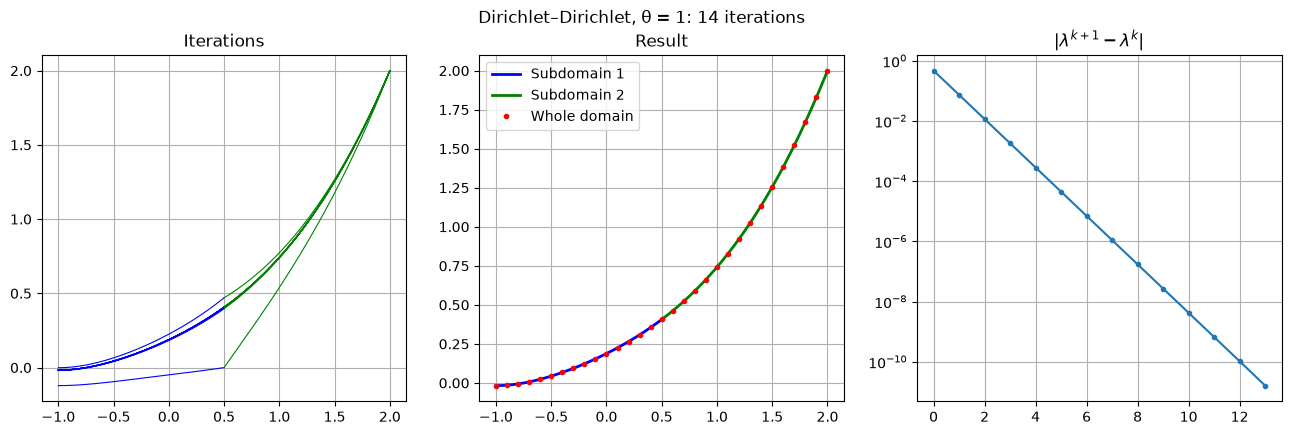

max|u - y_whole| = 1.39e-11


In [6]:
def dd1d(lam):
    x1, u1 = solve1d(-1, 0.5, nc, ("N", 0), ("D", lam))
    x2, u2 = solve1d(0.5, 2, N1 - nc, ("D", lam), ("D", 2))
    return (x1, u1, x2, u2), (flux1d(x2, u2, "L") - flux1d(x1, u1, "R")) / 2


show1d(*iterate(dd1d, 0, theta=1, eps=1e-10), "Dirichlet–Dirichlet, θ = 1")

## 2. 2D problem

$$
U_{xx} + U_{yy} = \sin xy, \quad x \in [-1, 1],\ y \in [0, 2]
$$

$$
U(-1, y) = \sin y, \quad U(1, y) = -2, \quad U(x, 0) = 3, \quad U(x, 2) = \cos x^2
$$

Subdomains are vertical strips; Neumann $U_x = g$ via ghost node as in 1D.

In [7]:
N = 100
x = np.linspace(-1, 1, N + 1)
y = np.linspace(0, 2, N + 1)
h = x[1] - x[0]
X, Y = np.meshgrid(x, y, indexing="ij")
F = np.sin(X * Y)
bot, top = 3 + 0 * x, np.cos(x**2)
lft = np.r_[bot[0], np.sin(y[1:-1]), top[0]]
rgt = np.r_[bot[-1], -2 + 0 * y[1:-1], top[-1]]


def d2(n, left_n=False, right_n=False):
    D = sp.diags([1, -2, 1], [-1, 0, 1], shape=(n, n), format="lil", dtype=float)
    if left_n:
        D[0, 1] = 2
    if right_n:
        D[-1, -2] = 2
    return D.tocsr() / h**2


def subdomain(i0, i1, lt="D", rt="D"):
    # strip i0..i1; solve(lv, rv) — column of U ("D") or of U_x ("N") on each side
    c0 = i0 if lt == "N" else i0 + 1
    c1 = i1 if rt == "N" else i1 - 1
    nx = c1 - c0 + 1
    A = sp.kron(d2(nx, lt == "N", rt == "N"), sp.eye(N - 1)) + sp.kron(sp.eye(nx), d2(N - 1))
    lu = splu(A.tocsc())

    def solve(lv, rv):
        U = np.zeros((i1 - i0 + 1, N + 1))
        U[:, 0], U[:, -1] = bot[i0:i1 + 1], top[i0:i1 + 1]
        R = F[c0:c1 + 1, 1:-1].copy()
        R[:, 0] -= bot[c0:c1 + 1] / h**2
        R[:, -1] -= top[c0:c1 + 1] / h**2
        if lt == "D":
            U[0] = lv
            R[0] -= lv[1:-1] / h**2
        else:
            R[0] += 2 * lv[1:-1] / h
        if rt == "D":
            U[-1] = rv
            R[-1] -= rv[1:-1] / h**2
        else:
            R[-1] -= 2 * rv[1:-1] / h
        U[c0 - i0:c1 - i0 + 1, 1:-1] = lu.solve(R.ravel()).reshape(nx, N - 1)
        return U

    return solve


def flux2d(U, i, side):
    # U_x on the side column, ghost node taken from the equation
    col, nb = (U[-1], U[-2]) if side == "R" else (U[0], U[1])
    ghost = F[i, 1:-1] * h**2 - col[2:] - col[:-2] + 4 * col[1:-1] - nb[1:-1]
    g = (ghost - nb[1:-1]) if side == "R" else (nb[1:-1] - ghost)
    return np.r_[0, g / (2 * h), 0]


def interface(cols):
    lam = np.zeros((len(cols), N + 1))
    lam[:, 0], lam[:, -1] = bot[cols], top[cols]
    return lam


Ug = subdomain(0, N)(lft, rgt)

In [8]:
cut = [0, 25, 50, 75, 100]                 # Γ_j: x = -0.5, 0, 0.5


def surf(ax, parts, title):
    for i0, i1, U in parts:
        ax.plot_surface(X[i0:i1 + 1], Y[i0:i1 + 1], U, cmap="jet", vmin=-2.2, vmax=3,
                        rstride=3, cstride=3, edgecolor="k", lw=0.15)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(title)


def show2d(Us, errs, title, its):
    fig = plt.figure(figsize=(17, 5))
    fig.suptitle(f"{title}: {len(errs)} iterations")
    for n, k in enumerate(its + [len(errs)]):
        U = Us[k - 1] if k < len(errs) else Us[-1]
        parts = [(cut[m], cut[m + 1], U[m]) for m in range(4)]
        surf(fig.add_subplot(1, 3, n + 1, projection="3d"), parts, f"iteration {k}")
    plt.show()
    plt.figure(figsize=(8, 4))
    plt.semilogy(errs)
    plt.xlabel("k")
    plt.ylabel(r"$\|\lambda^{k+1} - \lambda^k\|$")
    plt.grid()
    plt.show()
    U = Us[-1]
    print(f"max|U - U_whole| = {max(abs(U[m] - Ug[cut[m]:cut[m + 1] + 1]).max() for m in range(4)):.2e}")

### 2.1. Neumann–Dirichlet

$\Omega_1, \Omega_3$: $u|_{\Gamma_j} = \lambda_j^k$; $\quad\Omega_2, \Omega_4$: $\partial_x u|_{\Gamma_j}$ from neighbours; $\quad R_j = u_{2,4}|_{\Gamma_j} - \lambda_j^k$

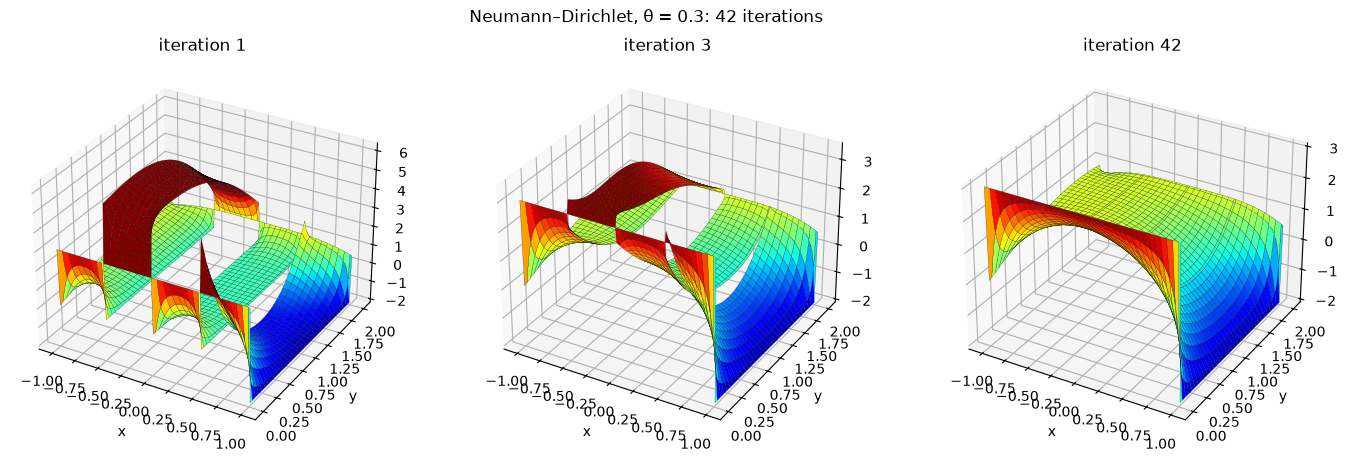

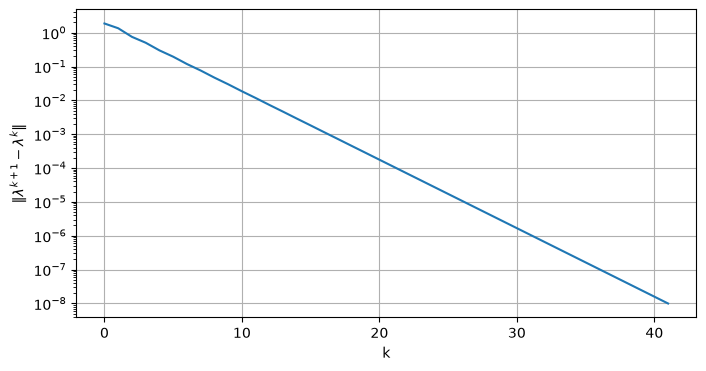

max|U - U_whole| = 2.69e-08


In [9]:
S = [subdomain(0, 25), subdomain(25, 50, "N", "N"), subdomain(50, 75), subdomain(75, 100, "N", "D")]


def nd2d(lam):
    U1 = S[0](lft, lam[0])
    U3 = S[2](lam[1], lam[2])
    U2 = S[1](flux2d(U1, 25, "R"), flux2d(U3, 50, "L"))
    U4 = S[3](flux2d(U3, 75, "R"), rgt)
    return [U1, U2, U3, U4], np.array([U2[0], U2[-1], U4[0]]) - lam


Us, errs = iterate(nd2d, interface(cut[1:-1]), theta=0.3)
show2d(Us, errs, "Neumann–Dirichlet, θ = 0.3", its=[1, 3])

### 2.2. Dirichlet–Dirichlet

$u|_{\Gamma_j} = \lambda_j^k$ for all subdomains; $\quad R_j = \tfrac12\left(\partial_x u_{j+1} - \partial_x u_j\right)\big|_{\Gamma_j}$

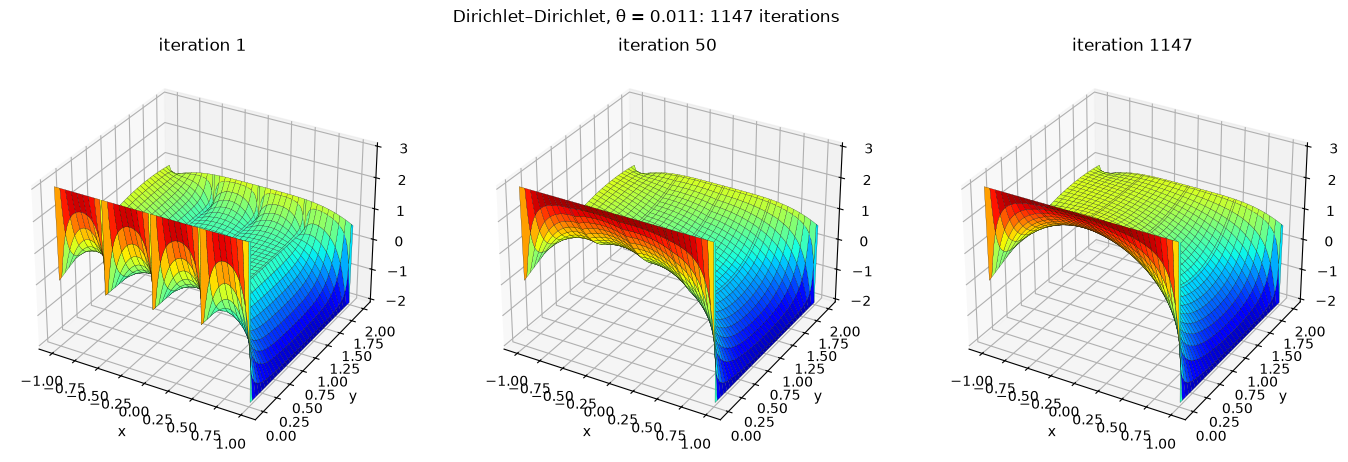

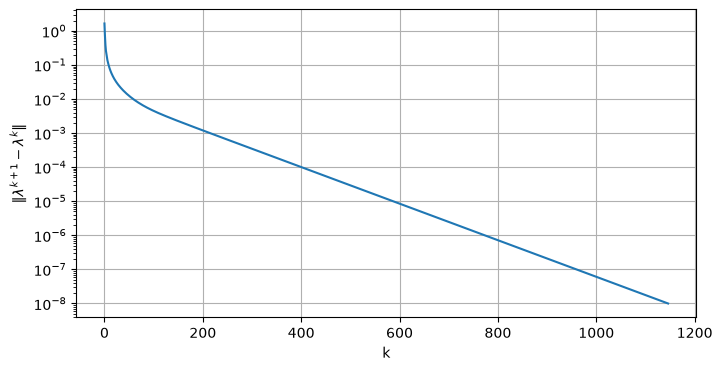

max|U - U_whole| = 8.11e-07


In [10]:
S = [subdomain(cut[m], cut[m + 1]) for m in range(4)]


def dd2d(lam):
    ends = [lft, *lam, rgt]
    U = [S[m](ends[m], ends[m + 1]) for m in range(4)]
    R = [(flux2d(U[j + 1], cut[j + 1], "L") - flux2d(U[j], cut[j + 1], "R")) / 2 for j in range(3)]
    return U, np.array(R)


Us, errs = iterate(dd2d, interface(cut[1:-1]), theta=0.011)
show2d(Us, errs, "Dirichlet–Dirichlet, θ = 0.011", its=[1, 50])

## 3. Overlapping subdomains

$\Omega_1 = [-1;\ 0.2]$, $\Omega_2 = [-0.2;\ 1]$, $G = \Omega_1 \cap \Omega_2$. Alternating Schwarz ($\theta = 1$):

$$
u_1^{k+1}\big|_{x = 0.2} = u_2^{k}\big|_{x = 0.2}, \qquad
u_2^{k+1}\big|_{x = -0.2} = u_1^{k+1}\big|_{x = -0.2}, \qquad
I^k = \iint_G \left(u_1^k - u_2^k\right)^2 dx\,dy
$$

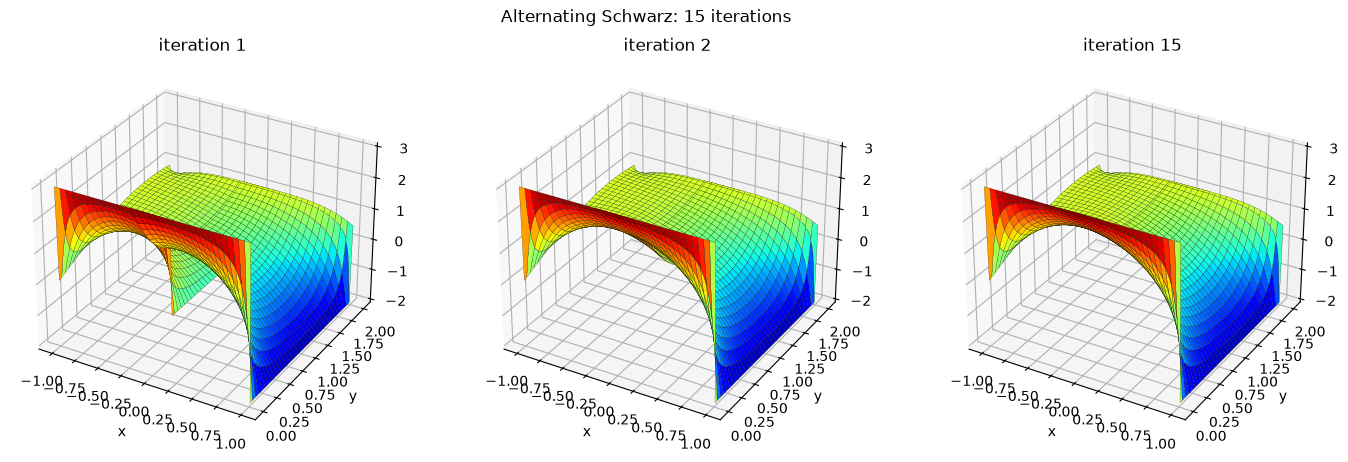

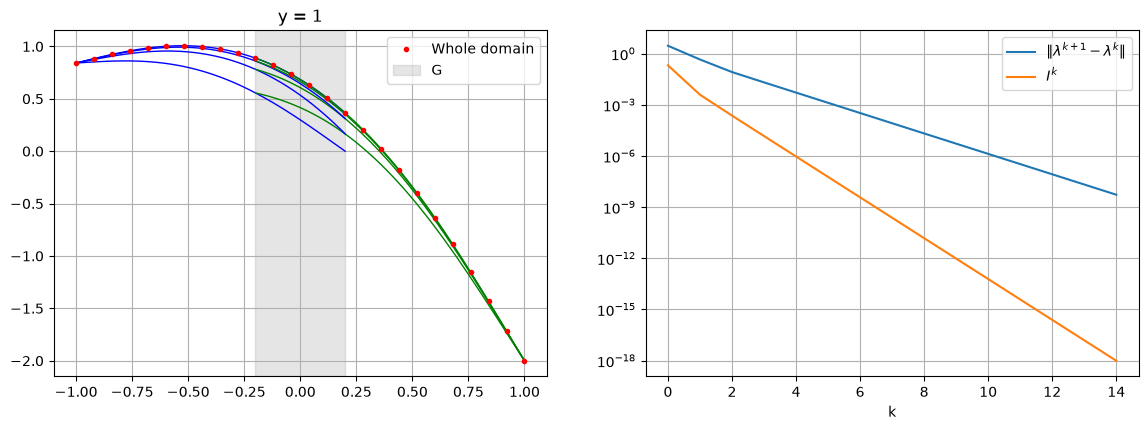

max|U - U_whole| = 3.59e-09


In [11]:
a, b = 40, 60
S1, S2 = subdomain(0, b), subdomain(a, N)


def schwarz(lam):
    U1 = S1(lft, lam[0])
    U2 = S2(U1[a], rgt)
    return (U1, U2), np.array([U2[b - a], U1[a]]) - lam


Us, errs = iterate(schwarz, interface([b, a]), theta=1, keep=1000)
I = [((U1[a:] - U2[:b - a + 1])**2).sum() * h * h for U1, U2 in Us[:-1]]

fig = plt.figure(figsize=(17, 5))
fig.suptitle(f"Alternating Schwarz: {len(errs)} iterations")
for n, k in enumerate([1, 2, len(errs)]):
    U1, U2 = Us[k - 1]
    surf(fig.add_subplot(1, 3, n + 1, projection="3d"), [(0, b, U1), (a, N, U2)], f"iteration {k}")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for U1, U2 in Us[:3] + Us[-1:]:
    ax[0].plot(x[:b + 1], U1[:, 50], "b", lw=1)
    ax[0].plot(x[a:], U2[:, 50], "g", lw=1)
ax[0].plot(x[::4], Ug[::4, 50], "r.", label="Whole domain")
ax[0].axvspan(x[a], x[b], color="gray", alpha=0.2, label="G")
ax[0].set_title("y = 1")
ax[0].legend()
ax[1].semilogy(errs, label=r"$\|\lambda^{k+1} - \lambda^k\|$")
ax[1].semilogy(I, label=r"$I^k$")
ax[1].set_xlabel("k")
ax[1].legend()
for a_ in ax:
    a_.grid()
plt.show()

U1, U2 = Us[-1]
print(f"max|U - U_whole| = {max(abs(U1 - Ug[:b + 1]).max(), abs(U2 - Ug[a:]).max()):.2e}")

### Висновки
1. Обидва методи без перекриття збігаються до розв'язку різницевої схеми на всій області.
2. 1D: Неймана–Діріхле — 11 ітерацій, Діріхле–Діріхле — 14.
3. 2D: Неймана–Діріхле — 42 ітерації; для Діріхле–Діріхле потрібне $\theta \sim h$, тому ітерацій понад тисячу.
4. Альтернуючий метод Шварца збігається за 15 ітерацій, $I^k \to 0$.